# Method 2: Ridge regression (the final model)
Learn the mapping from a low-minute profile to the full-season profile directly.

- **One model per (gender, position group)** for any number of minutes.
- **Features:** the per-90 of every volume stat in the group, entered as **z-scores against the training distribution at that many minutes** (12 fine minute bins, `distribution_norm.py`), the same z-scores times `s(m) = sqrt(250 / m)` (so the weight on the noisy value can fall as minutes grow), `log(minutes)`, matches played and minutes per match, standardized.
- **Targets:** the full-season per-90 of every stat. Weighted `RidgeCV` with a separate penalty per target (13 values from 0.01 to 10,000), weights = each player-season counts once per minutes bin.
- Predictions are clipped at 0 except the signed stats (`goals_minus_xg`, `xa_minus_assists`, `goals_prevented`, `np_goals`).
- Every stat's estimate can use every other stat, so it borrows strength across the profile.

**Setup shared by every method.** One model per gender and position group, trained on every per-game prefix (the player's first k matches, up to 750 minutes) of the 900+ minute player-seasons, each with its full-season per-90 as the target. The same fitted model handles any number of minutes. Rates, ratios and percents are never estimated: they are rebuilt from the estimated per-90 volumes.

In [1]:
%matplotlib inline
import sys, pathlib, warnings
warnings.filterwarnings("ignore")
# make the repo root importable no matter which folder the notebook is opened from
ROOT = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "low_minute_player_analysis").is_dir())
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from low_minute_player_analysis import notebook_helpers as nh
from low_minute_player_analysis import reconstruct_methods as rm
from low_minute_player_analysis import temporal_methods as tm
from low_minute_player_analysis import reconstruction_eval as ev

nh.apply_style()
r = nh.load_results("results")         # out-of-fold scores for every group, gender and method
V, R = nh.volume(r), nh.rates(r)       # volume stats / rates rebuilt from the estimated volumes
P = nh.load_paired("results")          # paired differences vs the final ridge, with bootstrap intervals
nh.describe(r)

79,101 scored rows | genders ['female', 'male'] | 7 groups | checkpoints [np.int64(250), np.int64(500), np.int64(750)] | methods ['raw', 'shrink', 'ridge', 'knn', 'ot_1d', 'ot_joint', 'ot_group', 'kalman', 'kalman_blend', 'ridge_kalman', 'gru']
volume stats scored: 113 | rebuilt rates scored: 74


## 1. Results across all 14 gender / position-group sets

**How to read the numbers.** `nrmse` is the RMSE of the estimate against the player's true full-season
per-90, divided by the standard deviation of that true value. 0 is perfect; 1 means no better than guessing
the group average. Every table shows the **median over stats** (and over groups/genders unless stated).
The three columns / x positions are **minutes bins** of the sample the estimate was made from: 250 = 0-375 minutes,
500 = 375-625, 750 = 625-750 (every per-game prefix of a held-out player is scored; each player-season counts once
per bin). Scores are out-of-fold: the 5 folds split players, so nobody is predicted by a model that saw them.

method,raw,ridge
checkpoint,,
250,1.489,0.769
500,0.713,0.552
750,0.518,0.457


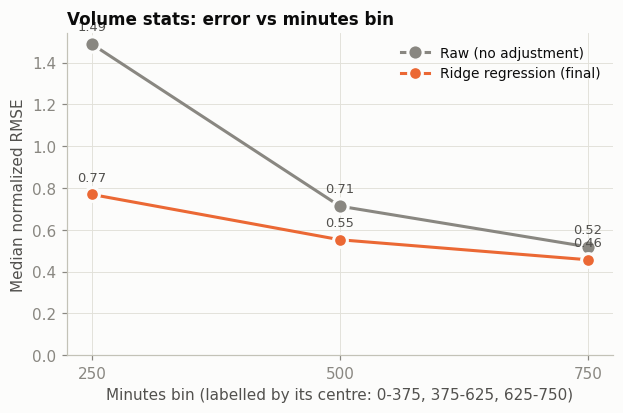

In [2]:
METHOD = "ridge"
METHODS = ["raw", METHOD]
summary = nh.median_nrmse(V, METHODS)
display(summary.round(3))
nh.curve_plot(summary, METHODS, "Volume stats: error vs minutes bin")
plt.show()

Error reduction versus raw (median over stats) and by position group:

method,ridge (% reduction)
minutes bin,
250,48.1
500,21.6
750,11.2


checkpoint,250,500,750
group,,,
Attacking Midfielders,44.3,18.0,8.2
Center Backs,50.4,23.9,14.9
Center Forwards,47.5,19.7,9.9
Central Midfielders,46.8,19.8,11.6
GK,55.4,31.5,14.5
Outside Backs,48.8,21.3,12.4
Wingers,46.1,18.2,5.9


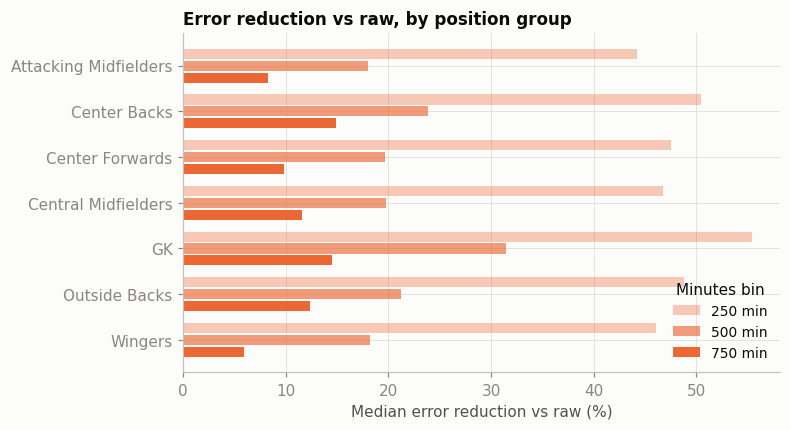

In [3]:
display(nh.improvement_table(V, [METHOD]).mul(100).round(1).rename_axis("minutes bin").add_suffix(" (% reduction)"))
by_group = nh.improvement_by_group(V, METHOD)
display(by_group.mul(100).round(1))
nh.group_bars(by_group, METHOD, "Error reduction vs raw, by position group")
plt.show()

Which stats improve most and least in the 500 bin?

In [4]:
best, worst = nh.per_stat(V, METHOD, 500)
display(pd.DataFrame({"most improved": best.mul(100).round(1)}))
display(pd.DataFrame({"least improved / worse": worst.mul(100).round(1)}))

,most improved
stat,
xa_minus_assists,38.6
third_assists,38.0
second_assists,38.0
goals_minus_xg,37.6
gk_clean_sheets,37.5
assists,37.0
goals_prevented,35.1
np_goals,34.8


,least improved / worse
stat,
offensive_duels,7.4
duels,7.9
free_kicks,8.1
corners,8.2
field_aerial_duels,9.0
field_aerial_duels_won,9.6
aerial_duels,9.8
aerial_duels_won,10.1


### Rates rebuilt from the estimated volumes
Percents, ratios and shares are **not** estimated directly. They are recomputed from the estimated per-90 volumes with the repo formulas (`rate_rebuild.py`). A rate is compared only where both the truth and the estimate exist; the share of rates the estimate could not produce is reported separately.

In [5]:
display(nh.median_nrmse(R, METHODS).round(3).rename_axis("minutes bin"))
display(nh.rate_table(R, METHODS, cp=500).round(3))
display(nh.missing_table(R, METHODS).round(4))

method,raw,ridge
minutes bin,,
250,1.737,0.857
500,0.838,0.654
750,0.610,0.564


method,raw,ridge
stat_type,,
rate_api_approx,0.844,0.642
rate_api_exact,1.031,0.820
rate_derived,0.754,0.573


,n_truth_ok,n_est_missing,n_compared,est_missing_share
method,,,,
raw,17532604,1039980,16492624,0.0593
ridge,17532604,162703,17369901,0.0093


## 2. Worked example: male Wingers (live run)
This re-runs the method out-of-fold on one group so every step below is reproducible here (the full results above came from `reconstruction_eval.py`).

raw     median nrmse @250/500/750: [1.378, 0.627, 0.451]
ridge   median nrmse @250/500/750: [0.745, 0.519, 0.417]


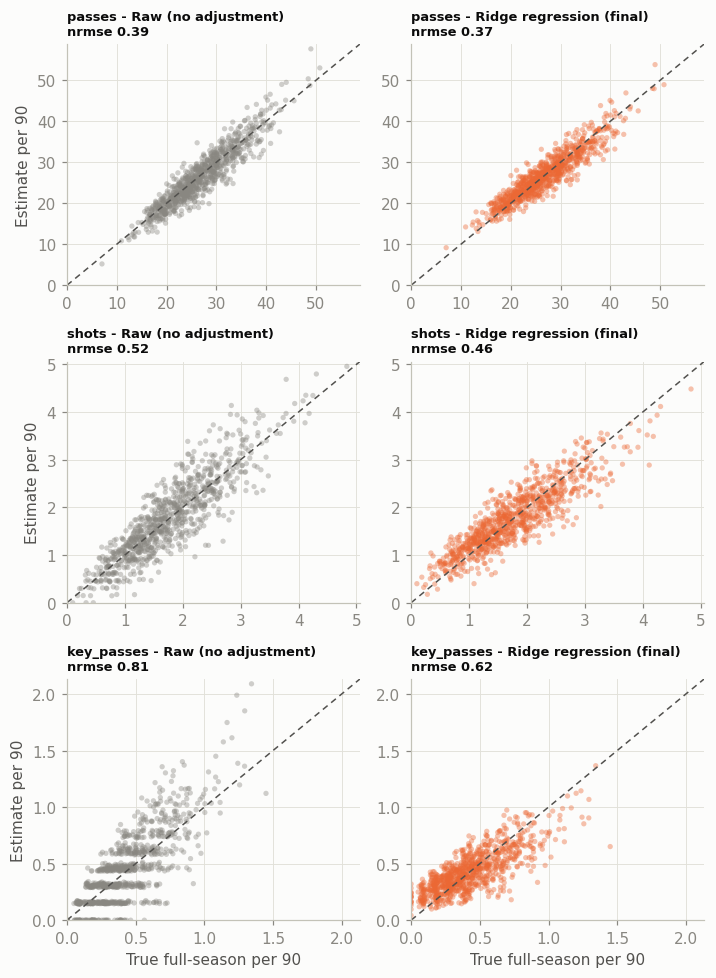

In [6]:
pool, stems, est = nh.demo_group("male", "Wingers", ["raw", METHOD])
for m in ["raw", METHOD]:
    print(f"{m:7s} median nrmse @250/500/750:",
          [round(float(nh.nrmse_per_stat(pool, est[m], b).median()), 3) for b in (250, 500, 750)])
fig = nh.scatter_grid(pool, est, ["passes", "shots", "key_passes"], 500, ["raw", METHOD])
plt.show()

### Diagnostic 1: why z-score against the distribution at that many minutes?
The spread of the low-minute per-90 across players shrinks as minutes grow (noise ~ 1 / minutes), and its level shifts (who keeps playing is selected). A single global scaler treats 1.5 shots per 90 at 100 minutes like 1.5 at 700 minutes.

,minutes bin centre,mean,sd across players
0,25.0,1.493,2.340
1,75.0,1.837,1.775
2,125.0,1.712,1.346
3,175.0,1.760,1.241
4,225.0,1.759,1.139
5,275.0,1.799,1.058
6,337.5,1.770,1.002
7,412.5,1.748,0.933
8,487.5,1.752,0.877
9,562.5,1.768,0.842


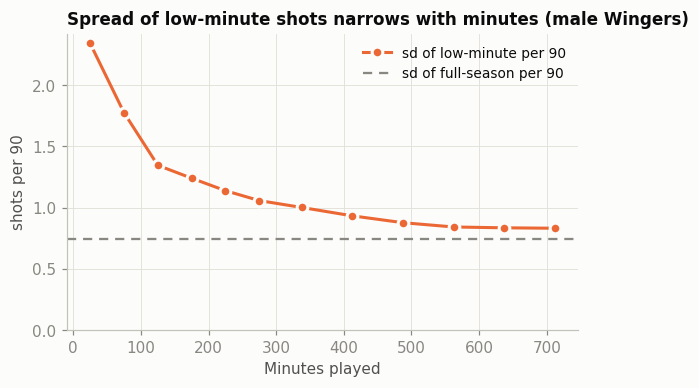

In [7]:
from low_minute_player_analysis.distribution_norm import FINE_EDGES, fit_minutes_norm
norm = fit_minutes_norm(rm.get_low(pool, stems), pool["actual_minutes"])
s = "shots"; i = stems.index(s)
centres = [(a + b) / 2 for a, b in zip(FINE_EDGES[:-1], FINE_EDGES[1:-1] + [750])]
tbl = pd.DataFrame({"minutes bin centre": centres, "mean": norm["mu"][:, i], "sd across players": norm["sd"][:, i]}).round(3)
display(tbl)
truth_sd = pool.drop_duplicates(["player_id", "year"])[f"full_{s}"].std()
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(centres, norm["sd"][:, i], marker="o", ms=7, lw=2, color=nh.COLORS["ridge"], markeredgecolor=nh.SURFACE, markeredgewidth=2, label="sd of low-minute per 90")
ax.axhline(truth_sd, color=nh.COLORS["raw"], lw=1.5, ls=(0, (4, 3)), label="sd of full-season per 90")
ax.set_xlabel("Minutes played"); ax.set_ylabel(f"{s} per 90"); ax.set_ylim(bottom=0)
ax.set_title(f"Spread of low-minute {s} narrows with minutes (male Wingers)", loc="left"); ax.legend(); plt.show()

### Diagnostic 2: penalties and what drives one prediction
Fitted on all of this group's prefixes (descriptive, not a validation score).

In [8]:
norm, sc, model = rm.fit_ridge(pool, stems)
names = rm.ridge_feature_names(stems)
alphas = pd.Series(model.alpha_, index=stems)
display(alphas.round(2).value_counts().sort_index().rename("number of stats").to_frame().rename_axis("alpha"))
target = "key_passes"
coefs = pd.Series(model.coef_[stems.index(target)], index=names)
display(coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(8).round(3).to_frame(f"standardized coefficient for {target}"))

,number of stats
alpha,
0.01,1
0.32,1
10.00,31
31.62,58
100.00,9


,standardized coefficient for key_passes
z:key_passes,0.065
z:shot_on_target_assists,0.065
z:successful_key_passes,0.057
z:passes_to_final_third,-0.022
z*s(m):successful_key_passes,-0.021
z*s(m):key_passes,-0.019
z*s(m):shot_on_target_assists,-0.019
z:successful_dribbles,-0.018


### Strengths and limits
- Best (or tied for best) on most stats at every minutes bin and in nearly every group; see the comparison notebook for the paired test.
- One model for any number of minutes, with a minutes-aware weight on the player's own data.
- Linear. It captures how stats move together on average but not interactions.